# ETL: superficies sin dano para el detector (v3)

El detector v2 aprendio que "foto de cerca de una pared = dano", porque casi todas sus fotos sin dano eran
habitaciones enteras. Este notebook agrega fotos **de cerca** de superficies **sanas** para corregirlo.

Fuentes (descargadas a mano en `data_superficies/`):
- **SDNET2018**, carpeta `W/UW`: paredes de hormigon sin fisura (Maguire, Dorafshan y Thomas, 2018).
- **Concrete Crack Images for Classification**, carpeta `Negative`: hormigon sin fisura (Ozgenel, 2019).
- **Opcional**: `data_superficies/propias/`, fotos propias de paredes sanas o capturas del simulador sin dano.

Pasos: muestra al azar, limpieza (archivos que no abren, muy chicos, duplicados), revision visual opcional y
subida a `s3://.../processed/damage_detection/undamaged_superficies/`. Las imagenes del bucket existentes no se tocan.

In [ ]:
# Celda 1: configuracion
# N_POR_FUENTE: cuantas imagenes se toman de cada dataset. Con 2.500 + 2.500
# alcanza para que el detector vea muchas paredes sanas de cerca sin que
# esas fotos dominen el dataset (las undamaged de deteccion son ~13.000).
# Las fotos propias (si hay) se usan todas.

import os
import io
import random
import hashlib
import shutil
import subprocess

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

SEED = 42
random.seed(SEED)

BASE = "../data_superficies"  # los datos quedan en notebooks/, fuera de parte3
FUENTES = {
    "sdnet_uw": f"{BASE}/SDNET2018/W/UW",
    "ozgenel_negative": f"{BASE}/5y9wdsg2zt-2/Concrete Crack Images for Classification/Negative",
    "propias": f"{BASE}/propias",
}
N_POR_FUENTE = 2500
MIN_LADO = 100  # descarta imagenes de menos de 100 px de lado
REVISAR = False  # True para revisar las imagenes a mano (celda 3) antes de subirlas

SALIDA_LOCAL = f"{BASE}/seleccion"
S3_DESTINO = "s3://humanoid-damage-cnn-834257582282-us-east-1-an/processed/damage_detection/undamaged_superficies"
FORMATOS_OK = (".jpg", ".jpeg", ".png", ".bmp")

for nombre, carpeta in FUENTES.items():
    n = len(os.listdir(carpeta)) if os.path.isdir(carpeta) else 0
    print(f"{nombre:18s} {n:6d} archivos  ({carpeta})")

In [ ]:
# Celda 2: muestra al azar y limpieza
# Para cada fuente toma una muestra un 20% mas grande que N_POR_FUENTE
# (para tener reemplazo de las que se descarten) y para cada archivo:
#   - chequea que abra con PIL y que no sea demasiado chico
#   - calcula el hash md5 para sacar duplicados exactos (dentro y entre fuentes)
# Las fotos propias no se muestrean, se usan todas.

def md5(ruta):
    with open(ruta, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

filas = []
vistos = set()
for fuente, carpeta in FUENTES.items():
    if not os.path.isdir(carpeta):
        continue
    archivos = sorted(a for a in os.listdir(carpeta) if a.lower().endswith(FORMATOS_OK))
    if fuente != "propias":
        archivos = random.sample(archivos, min(len(archivos), int(N_POR_FUENTE * 1.2)))
    descartes = {"no abre": 0, "chica": 0, "duplicada": 0}
    for a in archivos:
        ruta = f"{carpeta}/{a}"
        try:
            with Image.open(ruta) as im:
                im.verify()
            with Image.open(ruta) as im:
                ancho, alto = im.size
        except Exception:
            descartes["no abre"] += 1
            continue
        if min(ancho, alto) < MIN_LADO:
            descartes["chica"] += 1
            continue
        h = md5(ruta)
        if h in vistos:
            descartes["duplicada"] += 1
            continue
        vistos.add(h)
        filas.append({"fuente": fuente, "ruta": ruta, "archivo": a, "hash": h, "ancho": ancho, "alto": alto})
    print(f"{fuente:18s} candidatas OK: {sum(f['fuente'] == fuente for f in filas)}  descartes: {descartes}")

cand_df = pd.DataFrame(filas)

In [ ]:
# Celda 3: revision visual (OPCIONAL, solo si REVISAR = True en la celda 1)
# Muestra las candidatas de a 20. Tilda las que tengan alguna fisura,
# mancha u otro dano (no deberian ir como "sin dano") y apreta "Siguiente".
# Se puede cortar cuando quieras: lo no revisado se considera OK.
# Con REVISAR = False no muestra nada y se pueden correr las celdas
# siguientes directamente.

POR_PAGINA = 20
descartadas = set()
orden = cand_df.sample(frac=1, random_state=SEED).index.tolist()
estado = {"i": 0}

if REVISAR:
    # los widgets solo se cargan si se revisa (asi VS Code no pide nada con REVISAR = False)
    import ipywidgets as widgets
    from IPython.display import display, clear_output
    salida = widgets.Output()

def mostrar():
    with salida:
        clear_output(wait=True)
        pagina = orden[estado["i"]:estado["i"] + POR_PAGINA]
        if not pagina:
            print(f"Revision terminada. Descartadas: {len(descartadas)}")
            return
        fig, axes = plt.subplots(4, 5, figsize=(15, 12))
        for ax in axes.ravel():
            ax.axis("off")
        cajas = []
        for ax, idx in zip(axes.ravel(), pagina):
            ax.imshow(Image.open(cand_df.loc[idx, "ruta"]).convert("RGB"))
            ax.set_title(f"{len(cajas) + 1}", fontsize=10)
            cajas.append(widgets.Checkbox(value=idx in descartadas, description=f"{len(cajas) + 1} tiene dano",
                                          indent=False, layout=widgets.Layout(width="140px")))
        plt.tight_layout()
        plt.show()
        boton = widgets.Button(description="Siguiente", button_style="primary")
        def siguiente(_):
            for caja, idx in zip(cajas, pagina):
                (descartadas.add if caja.value else descartadas.discard)(idx)
            estado["i"] += POR_PAGINA
            mostrar()
        boton.on_click(siguiente)
        print(f"Imagenes {estado['i'] + 1}-{estado['i'] + len(pagina)} de {len(orden)} | descartadas: {len(descartadas)}")
        display(widgets.HBox(cajas[:10]), widgets.HBox(cajas[10:]), boton)

if REVISAR:
    display(salida)
    mostrar()
else:
    print("Revision salteada (REVISAR = False): se usan todas las candidatas")

In [ ]:
# Celda 4: seleccion final
# Saca las descartadas en la revision (si se hizo) y toma N_POR_FUENTE de
# cada dataset al azar (las propias se usan todas).
# A cada archivo le pone el nombre de la fuente adelante, porque los dos
# datasets usan nombres parecidos (00001.jpg) y asi no se pisan en S3.

try:
    descartadas
except NameError:
    descartadas = set()

ok_df = cand_df.drop(index=list(descartadas))
partes = []
for fuente, grupo in ok_df.groupby("fuente"):
    n = len(grupo) if fuente == "propias" else min(N_POR_FUENTE, len(grupo))
    partes.append(grupo.sample(n=n, random_state=SEED))
sel_df = pd.concat(partes, ignore_index=True)
sel_df["destino"] = sel_df["fuente"] + "/" + sel_df["fuente"] + "_" + sel_df["archivo"]

print(f"Descartadas en la revision: {len(descartadas)}")
print(sel_df["fuente"].value_counts().to_string())

In [5]:
# Celda 5: copia local y subida a S3
# Copia la seleccion a data_superficies/seleccion/<fuente>/ y la sincroniza
# con S3. "sync" solo sube lo que falta y nunca borra nada del bucket.
# Requiere el AWS CLI configurado (igual que los otros notebooks).

if os.path.isdir(SALIDA_LOCAL):
    shutil.rmtree(SALIDA_LOCAL)
for _, fila in sel_df.iterrows():
    destino = f"{SALIDA_LOCAL}/{fila['destino']}"
    os.makedirs(os.path.dirname(destino), exist_ok=True)
    shutil.copy2(fila["ruta"], destino)

sel_df.to_csv(f"{BASE}/seleccion_superficies.csv", index=False)
print(f"Copiadas {len(sel_df)} imagenes a {SALIDA_LOCAL}")

subprocess.run(["aws", "s3", "sync", SALIDA_LOCAL, S3_DESTINO, "--quiet"], check=True)
print(f"Subidas a {S3_DESTINO}")

Subidas a s3://humanoid-damage-cnn-834257582282-us-east-1-an/processed/damage_detection/undamaged_superficies


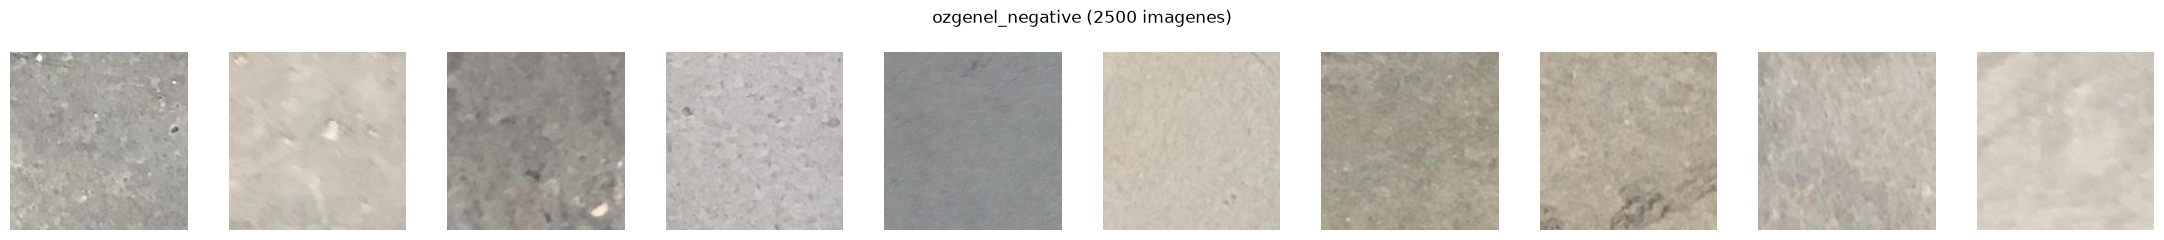

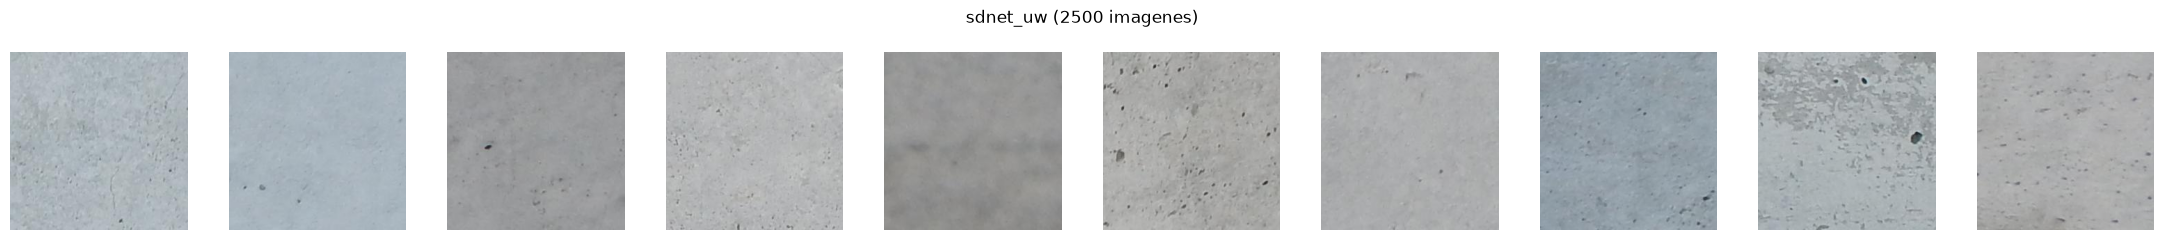

In [6]:
# Celda 6: control visual de lo que se subio
# Muestra 10 imagenes al azar de cada fuente seleccionada.

for fuente, grupo in sel_df.groupby("fuente"):
    muestra = grupo.sample(min(10, len(grupo)), random_state=1)
    fig, axes = plt.subplots(1, len(muestra), figsize=(2.2 * len(muestra), 2.4))
    for ax, (_, fila) in zip(list(axes) if len(muestra) > 1 else [axes], muestra.iterrows()):
        ax.imshow(Image.open(fila["ruta"]).convert("RGB"))
        ax.axis("off")
    fig.suptitle(f"{fuente} ({len(grupo)} imagenes)")
    plt.tight_layout()
    plt.show()